# Comparaison des expériences reviewed

Exécuter depuis le dossier du notebook, avec pandas, NumPy et Matplotlib. Ajouter une entrée à `EXPERIMENTS` pour comparer un nouveau benchmark. Le niveau patient donne le même poids à chaque patient. Pour inspecter les résultats par image, ajouter `"image"` à `LEVELS`. Les écarts appariés restent calculés par patient.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

BENCHMARKS = Path.cwd() / "runs" / "benchmarks"
EXPERIMENTS = [
    ("Reviewed", "yolo26n_seg_512_seed42_reviewed_v1_20261109T171700_952430Z"),
    ("Sans mosaïque", "yolo26n_seg_512_seed42_r_nomosaic_20261113T164339_384226Z"),
    ("Sans miroir horizontal", "yolo26n_seg_512_seed42_r_nofliplr_20261113T164147_355977Z"),
    ("Géométrie douce", "yolo26n_seg_512_seed42_r_softgeom_20261113T164628_708269Z"),
    ("Rotation 5°", "yolo26n_seg_512_seed42_r_rot5_20261113T164514_328308Z"),
    ("Miroir vertical 0,1", "yolo26n_seg_512_seed42_r_flipud01_20261113T163854_671515Z"),
]
REFERENCE = "Reviewed"
LEVELS = ("patient",)  # ("patient", "image") pour afficher les deux niveaux.
METRICS = {"dice": "Dice", "iou": "IoU"}

Les exports sont appariés par identifiant patient et nom d’image. La comparaison vérifie aussi le côté, le fold de validation et le nombre de vues par patient.

In [2]:
def load_scores(path, key, identity):
    frame = pd.read_csv(path, dtype=str, keep_default_na=False)
    required = [*identity, *METRICS]
    if not set(required).issubset(frame):
        raise ValueError(f"Colonnes manquantes dans {path}")
    frame = frame[required].apply(lambda column: column.str.strip())
    if frame.empty or frame[identity].eq("").any().any() or frame[key].duplicated().any():
        raise ValueError(f"Identifiants vides ou dupliqués dans {path}")
    for metric in METRICS:
        frame[metric] = pd.to_numeric(frame[metric], errors="raise")
        if not frame[metric].between(0, 1).all():
            raise ValueError(f"Score {metric} hors de [0, 1] dans {path}")
    return frame.set_index(key).sort_index()


names = [name for name, _ in EXPERIMENTS]
if len(names) != len(set(names)) or REFERENCE not in names:
    raise ValueError("Utiliser des noms uniques et indiquer une référence dans EXPERIMENTS.")
if not LEVELS or not set(LEVELS) <= {"image", "patient"}:
    raise ValueError("LEVELS doit contenir patient et/ou image.")

scores = {"image": {}, "patient": {}}
for name, directory in EXPERIMENTS:
    folder = BENCHMARKS / directory
    images = load_scores(folder / "per_image.csv", "NAME", ["NAME", "PATIENT", "SIDE", "fold"])
    patients = load_scores(folder / "per_patient.csv", "PATIENT", ["PATIENT", "fold", "n_images"])
    grouped = images.groupby("PATIENT")
    if (not grouped.size().index.equals(patients.index)
            or not grouped.size().equals(patients.n_images.astype(int))
            or not grouped.fold.nunique().eq(1).all()
            or not grouped.fold.first().equals(patients.fold)
            or not np.allclose(grouped[list(METRICS)].mean(), patients[list(METRICS)], atol=1e-9, rtol=0)):
        raise ValueError(f"Les exports image et patient divergent pour {name}.")
    scores["image"][name] = images
    scores["patient"][name] = patients

for level, columns in {"image": ["PATIENT", "SIDE", "fold"], "patient": ["fold", "n_images"]}.items():
    reference = scores[level][REFERENCE][columns]
    for name, frame in scores[level].items():
        if not frame[columns].equals(reference):
            raise ValueError(f"{name} et {REFERENCE} diffèrent au niveau {level} (identifiants, vues ou folds).")
print(f"{len(names)} expériences appariées sur {len(scores['patient'][REFERENCE])} patients "
      f"et {len(scores['image'][REFERENCE])} images.")

6 expériences appariées sur 42 patients et 80 images.


### Tableau récapitulatif

Les scores sont exprimés en pourcentage. L’écart-type est celui de l’échantillon (`ddof=1`), exprimé en points de pourcentage.

In [3]:
for level in LEVELS:
    rows = []
    for name in names:
        for metric, label in METRICS.items():
            values = 100 * scores[level][name][metric]
            rows.append({
                "Expérience": name, "Métrique": label, "Effectif": len(values),
                "Moyenne": values.mean(), "Écart-type": values.std(ddof=1),
                "Médiane": values.median(), "Minimum": values.min(), "Maximum": values.max(),
            })
    print(f"Statistiques par {level}")
    display(pd.DataFrame(rows).set_index(["Expérience", "Métrique"]).round(2))

Statistiques par patient


Effectif  Moyenne  Écart-type  Médiane  \
Expérience             Métrique                                           
Reviewed               Dice            42    95.37        2.49    96.07   
                       IoU             42    91.29        4.37    92.45   
Sans mosaïque          Dice            42    94.89        2.85    95.52   
                       IoU             42    90.45        4.90    91.43   
Sans miroir horizontal Dice            42    95.04        2.27    95.70   
                       IoU             42    90.67        4.02    91.78   
Géométrie douce        Dice            42    95.38        2.22    95.83   
                       IoU             42    91.28        3.96    92.04   
Rotation 5°            Dice            42    95.30        2.50    96.01   
                       IoU             42    91.15        4.32    92.35   
Miroir vertical 0,1    Dice            42    94.72        3.45    95.30   
                       IoU             42    90.23        5.61    91.03   

                                 Minimum  Maximum  
Expérience             Métrique                    
Reviewed               Dice        87.59    98.22  
                       IoU         77.97    96.50  
Sans mosaïque          Dice        84.34    98.37  
                       IoU         73.40    96.79  
Sans miroir horizontal Dice        88.24    98.29  
                       IoU         79.27    96.64  
Géométrie douce        Dice        88.32    98.56  
                       IoU         79.10    97.17  
Rotation 5°            Dice        84.14    98.19  
                       IoU         72.88    96.45  
Miroir vertical 0,1    Dice        79.72    98.46  
                       IoU         66.93    96.97

### Minimum, maximum, moyenne et médiane

Chaque trait relie les deux scores extrêmes. Le rond indique la moyenne et le losange la médiane. La référence est en orange dans toutes les figures.

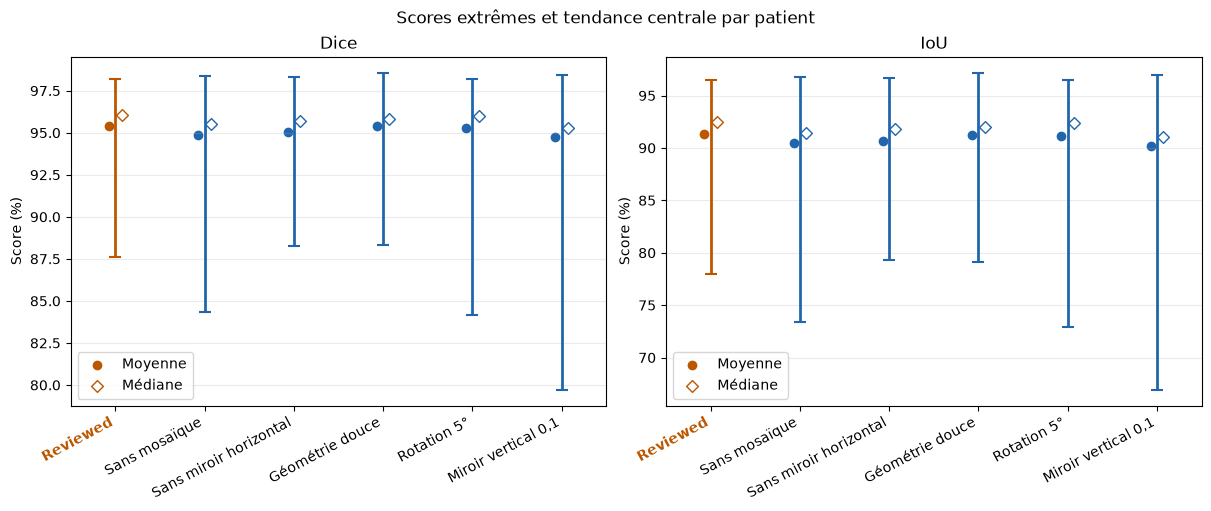

In [4]:
def panels(labels):
    fig, axes = plt.subplots(1, 2, figsize=(max(12, 1.9 * len(labels)), 5), layout="constrained")
    for ax in axes:
        ax.set_xticks(range(1, len(labels) + 1), labels, rotation=28, ha="right")
        ax.grid(axis="y", alpha=0.25)
        for tick, label in zip(ax.get_xticklabels(), labels):
            if label == REFERENCE:
                tick.set_color("#bc5700")
                tick.set_fontweight("bold")
    return fig, axes


def color(name):
    return "#bc5700" if name == REFERENCE else "#2166ac"


for level in LEVELS:
    fig, axes = panels(names)
    for ax, (metric, label) in zip(axes, METRICS.items()):
        for x, name in enumerate(names, 1):
            values = 100 * scores[level][name][metric]
            ax.vlines(x, values.min(), values.max(), color=color(name), linewidth=2)
            ax.scatter([x, x], [values.min(), values.max()], marker="_", color=color(name), s=85)
            ax.scatter(x - 0.07, values.mean(), color=color(name), marker="o", label="Moyenne" if x == 1 else None)
            ax.scatter(x + 0.07, values.median(), facecolors="white", edgecolors=color(name),
                       marker="D", label="Médiane" if x == 1 else None)
        ax.set(title=label, ylabel="Score (%)", xlim=(0.5, len(names) + 0.5))
        ax.legend()
    fig.suptitle(f"Scores extrêmes et tendance centrale par {level}")
    plt.show()

### Distributions

Chaque point représente un patient, ou une image si ce niveau est activé. Les boîtes couvrent les 50 % centraux. Les moustaches s’étendent jusqu’aux observations situées à au plus 1,5 fois l’écart interquartile au-delà de la boîte. Tous les points sont affichés.

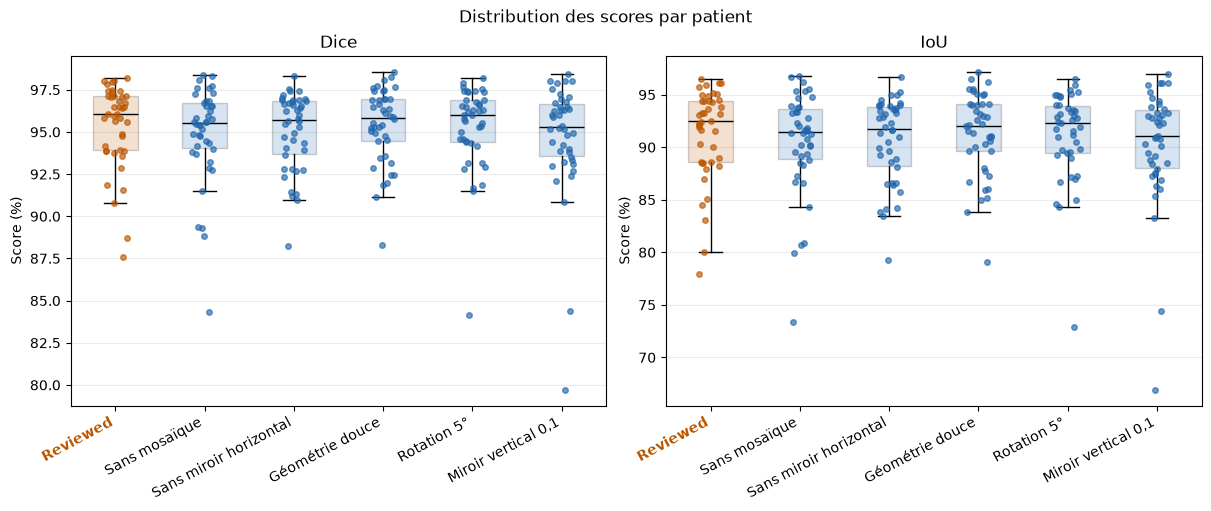

In [6]:
def plot_distributions(frames, labels, title, ylabel, *, zero_line=False):
    fig, axes = panels(labels)
    rng = np.random.default_rng(42)
    for ax, (metric, label) in zip(axes, METRICS.items()):
        groups = [100 * frames[name][metric].to_numpy() for name in labels]
        boxes = ax.boxplot(groups, patch_artist=True, showfliers=False, manage_ticks=False,
                           medianprops={"color": "black"})
        for x, (name, values, box) in enumerate(zip(labels, groups, boxes["boxes"]), 1):
            box.set_facecolor(color(name))
            box.set_alpha(0.18)
            ax.scatter(x + rng.uniform(-0.14, 0.14, len(values)), values,
                       s=16, color=color(name), alpha=0.65, zorder=3)
        if zero_line:
            ax.axhline(0, color="black", linestyle="--", linewidth=1)
        ax.set(title=label, ylabel=ylabel, xlim=(0.5, len(labels) + 0.5))
    fig.suptitle(title)
    plt.show()


for level in LEVELS:
    plot_distributions(scores[level], names, f"Distribution des scores par {level}", "Score (%)")

### Écarts par patient face à la référence

Chaque point correspond au score de l’essai moins celui de la référence pour le même patient. Une valeur positive indique une amélioration. Les différences sont exprimées en points de pourcentage.

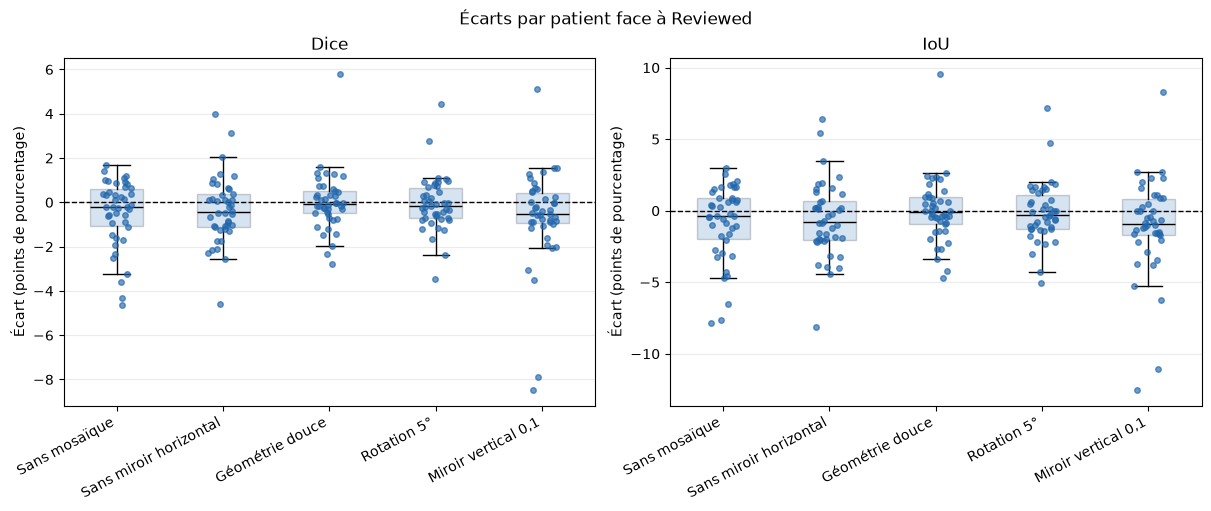

In [7]:
trials = [name for name in names if name != REFERENCE]
if trials:
    reference_scores = scores["patient"][REFERENCE][list(METRICS)]
    differences = {name: scores["patient"][name][list(METRICS)] - reference_scores for name in trials}
    plot_distributions(differences, trials, f"Écarts par patient face à {REFERENCE}",
                       "Écart (points de pourcentage)", zero_line=True)
else:
    print("Ajouter au moins un essai pour afficher les écarts face à la référence.")